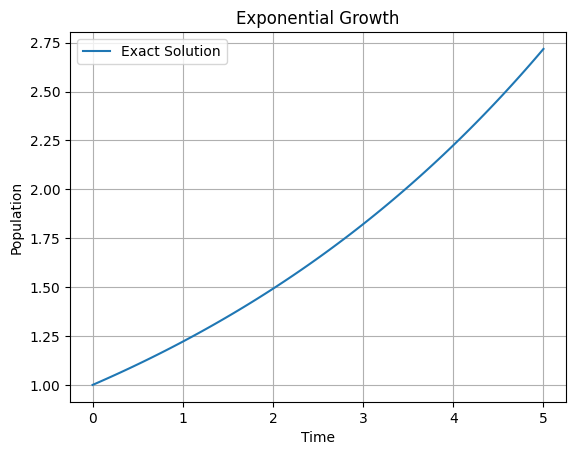

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Analytic solution
def solution(t, P0, A):
    return P0 * np.exp(A * t)

t = np.linspace(0, 5, 100)   # Time points
A = 0.2                      # Growth rate
P0 = 1                       # Initial population

Pt_exact = solution(t, P0, A) # Exact solution

plt.plot(t, Pt_exact, label='Exact Solution')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Exponential Growth')
plt.legend()
plt.grid(True)
plt.savefig("pop_exact.png", bbox_inches='tight')
plt.show()

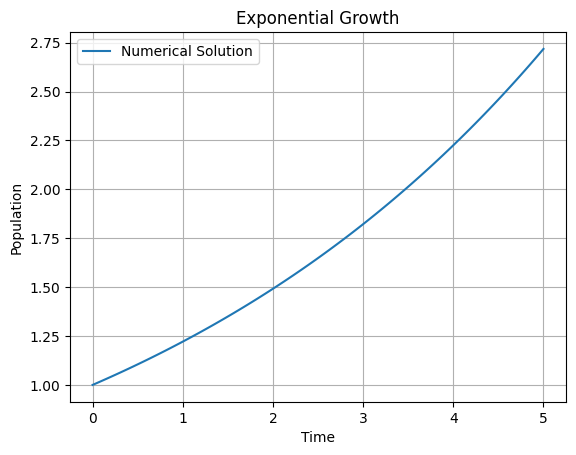

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Growth model, R.H.S 
def growth(P, t, A):
    return A * P

t = np.linspace(0, 5, 100)   # Time points
A = 0.2                      # Growth rate
P0 = 1                       # Initial population

Pt_numerical = odeint(growth, P0, t, args=(A,)) # Numerical solution

plt.plot(t, Pt_numerical, label='Numerical Solution')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Exponential Growth')
plt.legend()
plt.grid(True)
plt.savefig("pop_num.png", bbox_inches='tight')
plt.show()

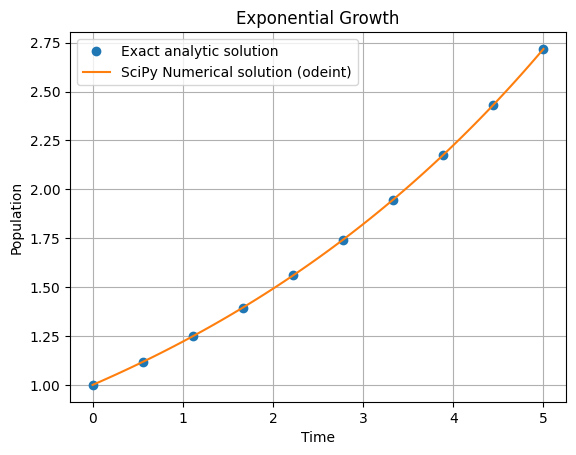

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Analytic solution
def solution(t, P0, A):
    return P0 * np.exp(A * t)

# Exponential growth model
def growth(P, t, A):
    return A * P


A = 0.2                      # Growth rate
P0 = 1                       # Initial population

t_discrete = np.linspace(0, 5, 10) # Fewer time values to plot exact solution
Pt_exact = solution(t_discrete, P0, A) # Exact analytic solution

t = np.linspace(0, 5, 100)   # Time points
Pt_numerical = odeint(growth, P0, t, args=(A,)) # Solve the ODE numerically

plt.plot(t_discrete, Pt_exact, label='Exact analytic solution', linestyle='', marker='o')
plt.plot(t, Pt_numerical, label='SciPy Numerical solution (odeint)')

plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Exponential Growth')
plt.legend()
plt.grid(True)
plt.savefig("pop_both.png", bbox_inches='tight')
plt.show()

# Growth with attrition

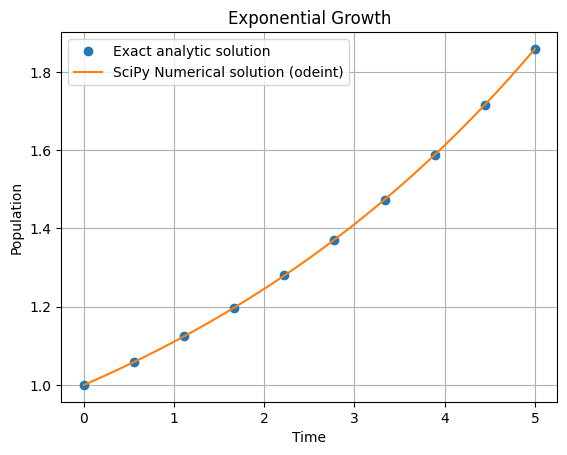

In [4]:
# Exponential growth with constant attrition
def growth(P, t, A, B):
    return A * P - B

# Analytic solution
def solution(t, P0, A, B):
    return (P0 - B/A) * np.exp(A * t) + B/A

# A: Growth rate, B: Attrition rate, P0: Initial population
A, B, P0 = 0.2, 0.1, 1                      

t_discrete = np.linspace(0, 5, 10) # Fewer time values to plot exact solution
Pt_exact = solution(t_discrete, P0, A, B) # Exact analytic solution

t = np.linspace(0, 5, 100)   # Time points
Pt_numerical = odeint(growth, P0, t, args=(A,B)) # Solve the ODE numerically

plt.plot(t_discrete, Pt_exact, label='Exact analytic solution', linestyle='', marker='o')
plt.plot(t, Pt_numerical, label='SciPy Numerical solution (odeint)')

plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Exponential Growth')
plt.legend()
plt.grid(True)
plt.savefig("pop_with_attrition_both.png", bbox_inches='tight')
plt.show()

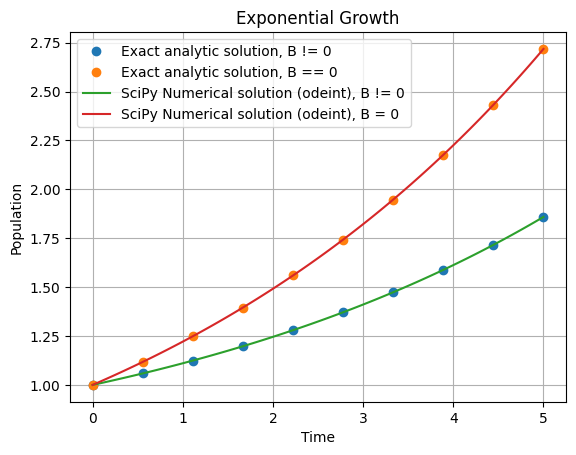

In [5]:
# Exponential growth with constant attrition
def growth(P, t, A, B):
    return A * P - B

# Analytic solution
def solution(t, P0, A, B):
    return (P0 - B/A) * np.exp(A * t) + B/A

# A: Growth rate, B: Attrition rate, P0: Initial population
A, B, P0 = 0.2, 0.1, 1                      

t_discrete = np.linspace(0, 5, 10) # Fewer time values to plot exact solution
Pt_exact_1 = solution(t_discrete, P0, A, B) # Exact analytic solution, B /= 0
Pt_exact_2 = solution(t_discrete, P0, A, 0) # Exact analytic solution, B = 0

plt.plot(t_discrete, Pt_exact_1, label='Exact analytic solution, B != 0', linestyle='', marker='o')
plt.plot(t_discrete, Pt_exact_2, label='Exact analytic solution, B == 0', linestyle='', marker='o')

t = np.linspace(0, 5, 100)   # Time points
Pt_numerical1 = odeint(growth, P0, t, args=(A,B)) # Solve the ODE numerically
Pt_numerical2 = odeint(growth, P0, t, args=(A,0)) # Solve the ODE numerically

plt.plot(t, Pt_numerical1, label='SciPy Numerical solution (odeint), B != 0')
plt.plot(t, Pt_numerical2, label='SciPy Numerical solution (odeint), B = 0')

plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Exponential Growth')
plt.legend()
plt.grid(True)
plt.savefig("pop_with_attrition_both.png", bbox_inches='tight')
plt.show()

# Logistic

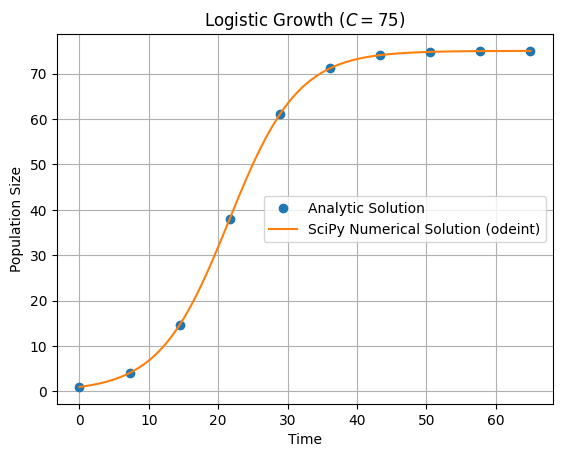

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Logistic growth differential equation
def growth(P, t, A, C):
    return A * P * (1 - P / C)

# Analytic solution to the logistic equation
def solution(t, P0, A, C):
    return C / (1 + ((C - P0) / P0) * np.exp(-A * t))

# Parameters and initial condition
P0 = 1       # Initial population
A = 0.2      # Growth rate
C = 75       # Carrying capacity

# Time points
t = np.linspace(0, 65, 100)   # Dense for odeint
t_discrete = np.linspace(0, 65, 10) 

# Solve numerically with odeint
Pt_numerical = odeint(growth, P0, t, args=(A, C))

# Solve analytically
Pt_exact = solution(t_discrete, P0, A, C)

# Plot the results
plt.plot(t_discrete, Pt_exact, label='Analytic Solution', linestyle='', marker='o')
plt.plot(t, Pt_numerical, label='SciPy Numerical Solution (odeint)', linestyle='-')
plt.xlabel('Time')
plt.ylabel('Population Size')
plt.title('Logistic Growth ($C=75$)')
plt.legend(loc='right')
plt.grid(True)
plt.savefig("logistic.png", bbox_inches='tight')
plt.show()

# Reaction model

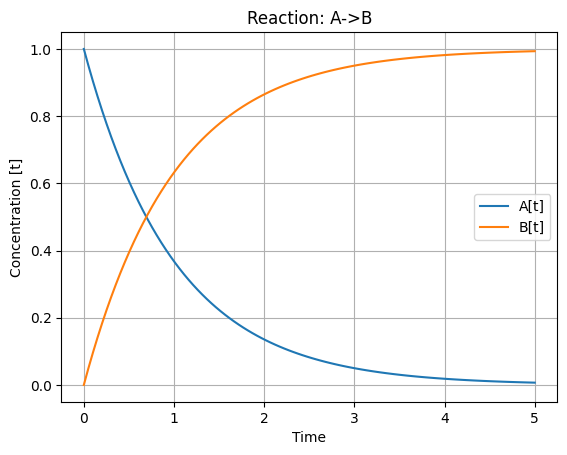

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def rxn_AB(A, t, k1):
    dAdt = -k1 * A   # this is the RHS of d[A]/dt=-k1[A]
    return dAdt

A0, k1 = 1, 1                     

t = np.linspace(0, 5, 100)   
A_t = odeint(rxn_AB, A0, t, args=(k1,)) 
B_t = A0-A_t

plt.plot(t, A_t, label='A[t]')
plt.plot(t, B_t, label='B[t]')

plt.xlabel('Time')
plt.ylabel('Concentration [t]')
plt.title('Reaction: A->B')
plt.legend()
plt.grid(True)
plt.savefig("rxn_AB.png", bbox_inches='tight')
plt.show()

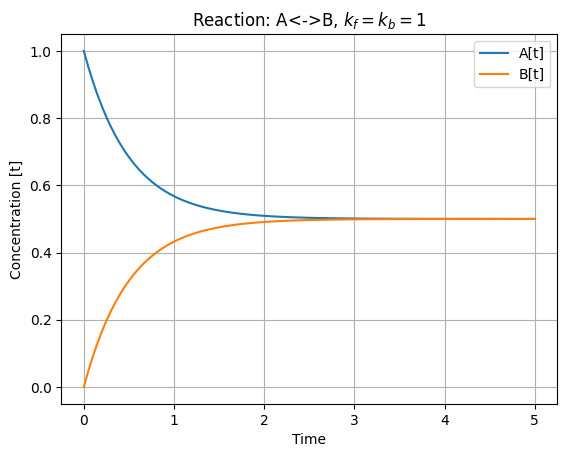

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def rxn_AB_rev(P, t, kf, kb):
    A, B = P[0], P[1]
    dAdt = -kf * A + kb * B   # this is the RHS of d[A]/dt=-kf[A] + kb[B]
    dBdt = -kb * B + kf * A   # this is the RHS of d[B]/dt=-kb[B] + kf[A]
    return dAdt, dBdt

A0, B0, kf, kb = 1, 0, 1, 1                     

t = np.linspace(0, 5, 100)   
P_t = odeint(rxn_AB_rev, [A0, B0], t, args=(kf, kb)) 

A_t, B_t = P_t[:,0], P_t[:,1]
plt.plot(t, A_t, label='A[t]')
plt.plot(t, B_t, label='B[t]')

plt.xlabel('Time')
plt.ylabel('Concentration [t]')
plt.title('Reaction: A<->B, $k_f=k_b=1$')
plt.legend()
plt.grid(True)
plt.savefig("rxn_AB_rev.png", bbox_inches='tight')
plt.show()

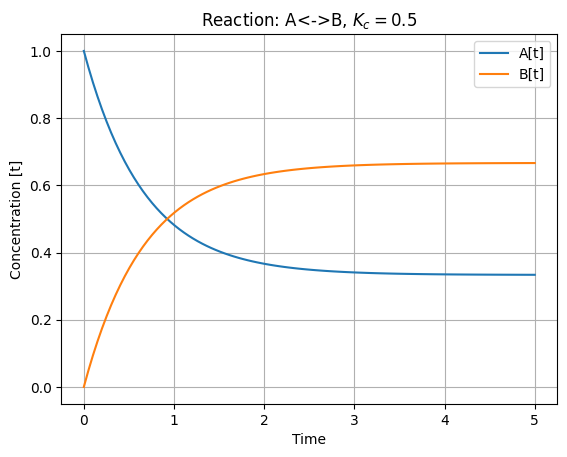

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def rxn_AB_rev(P, t, Kc):
    kf = 1
    kb = Kc / kf
    A, B = P[0], P[1]
    dAdt = -kf * A + kb * B   # this is the RHS of d[A]/dt=-kf[A] + kb[B]
    dBdt = -kb * B + kf * A   # this is the RHS of d[B]/dt=-kb[B] + kf[A]
    return dAdt, dBdt

A0, B0, Kc = 1, 0, 0.5             

t = np.linspace(0, 5, 100)   
P_t = odeint(rxn_AB_rev, [A0, B0], t, args=(Kc,)) 

A_t, B_t = P_t[:,0], P_t[:,1]
plt.plot(t, A_t, label='A[t]')
plt.plot(t, B_t, label='B[t]')

plt.xlabel('Time')
plt.ylabel('Concentration [t]')
plt.title('Reaction: A<->B, $K_c=0.5$')
plt.legend()
plt.grid(True)
plt.savefig("rxn_AB_rev_Kc1.png", bbox_inches='tight')
plt.show()

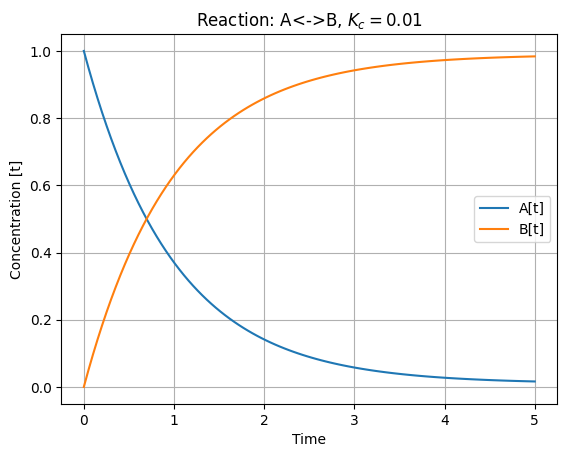

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def rxn_AB_rev(P, t, Kc):
    kf = 1
    kb = Kc / kf
    A, B = P[0], P[1]
    dAdt = -kf * A + kb * B   # this is the RHS of d[A]/dt=-kf[A] + kb[B]
    dBdt = -kb * B + kf * A   # this is the RHS of d[B]/dt=-kb[B] + kf[A]
    return dAdt, dBdt

A0, B0, Kc = 1, 0, 0.01             

t = np.linspace(0, 5, 100)   
P_t = odeint(rxn_AB_rev, [A0, B0], t, args=(Kc,)) 

A_t, B_t = P_t[:,0], P_t[:,1]
plt.plot(t, A_t, label='A[t]')
plt.plot(t, B_t, label='B[t]')

plt.xlabel('Time')
plt.ylabel('Concentration [t]')
plt.title('Reaction: A<->B, $K_c=0.01$')
plt.legend()
plt.grid(True)
plt.savefig("rxn_AB_rev_Kc2.png", bbox_inches='tight')
plt.show()

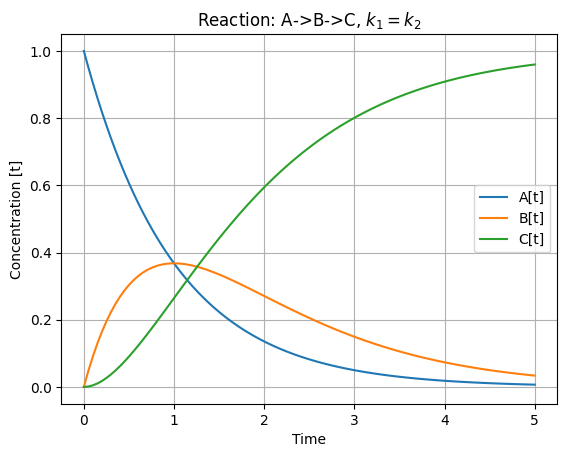

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def rxn_ABC_1(P, t, k1, k2):
    A, B = P[0], P[1]
    dAdt = -k1 * A 
    dBdt = k1 * A - k2 * B 
    return dAdt, dBdt

A0, B0, k1, k2 = 1, 0, 1, 1          

t = np.linspace(0, 5, 100)   
P_t = odeint(rxn_ABC_1, [A0, B0], t, args=(k1, k2)) 

A_t, B_t = P_t[:,0], P_t[:,1]
C_t = A0 - A_t - B_t

plt.plot(t, A_t, label='A[t]')
plt.plot(t, B_t, label='B[t]')
plt.plot(t, C_t, label='C[t]')

plt.xlabel('Time')
plt.ylabel('Concentration [t]')
plt.title('Reaction: A->B->C, $k_1=k_2$')
plt.legend()
plt.grid(True)
plt.savefig("rxn_ABC_1.png", bbox_inches='tight')
plt.show()

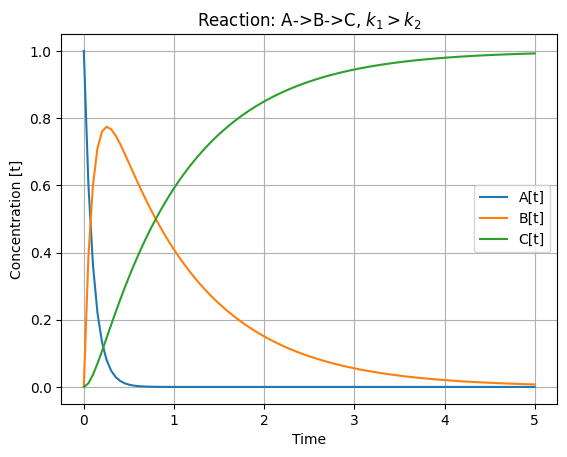

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def rxn_ABC_1(P, t, k1, k2):
    A, B = P[0], P[1]
    dAdt = -k1 * A 
    dBdt = k1 * A - k2 * B 
    return dAdt, dBdt

A0, B0, k1, k2 = 1, 0, 10, 1          

t = np.linspace(0, 5, 100)   
P_t = odeint(rxn_ABC_1, [A0, B0], t, args=(k1, k2)) 

A_t, B_t = P_t[:,0], P_t[:,1]
C_t = A0 - A_t - B_t

plt.plot(t, A_t, label='A[t]')
plt.plot(t, B_t, label='B[t]')
plt.plot(t, C_t, label='C[t]')

plt.xlabel('Time')
plt.ylabel('Concentration [t]')
plt.title('Reaction: A->B->C, $k_1>k_2$')
plt.legend()
plt.grid(True)
plt.savefig("rxn_ABC_2.png", bbox_inches='tight')
plt.show()

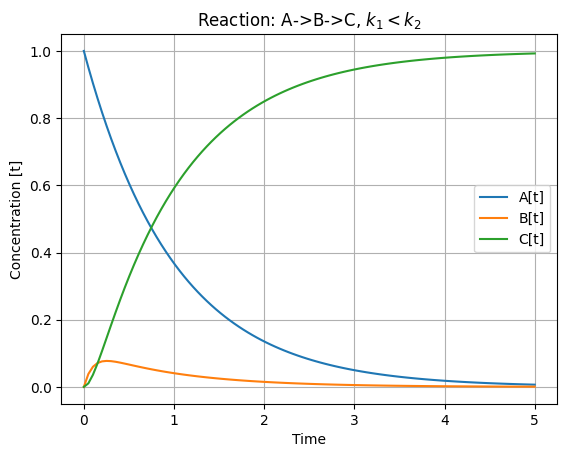

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def rxn_ABC_1(P, t, k1, k2):
    A, B = P[0], P[1]
    dAdt = -k1 * A 
    dBdt = k1 * A - k2 * B 
    return dAdt, dBdt

A0, B0, k1, k2 = 1, 0, 1, 10          

t = np.linspace(0, 5, 100)   
P_t = odeint(rxn_ABC_1, [A0, B0], t, args=(k1, k2)) 

A_t, B_t = P_t[:,0], P_t[:,1]
C_t = A0 - A_t - B_t

plt.plot(t, A_t, label='A[t]')
plt.plot(t, B_t, label='B[t]')
plt.plot(t, C_t, label='C[t]')

plt.xlabel('Time')
plt.ylabel('Concentration [t]')
plt.title('Reaction: A->B->C, $k_1<k_2$')
plt.legend()
plt.grid(True)
plt.savefig("rxn_ABC_3.png", bbox_inches='tight')
plt.show()

# Lotka-Volterra dynamics

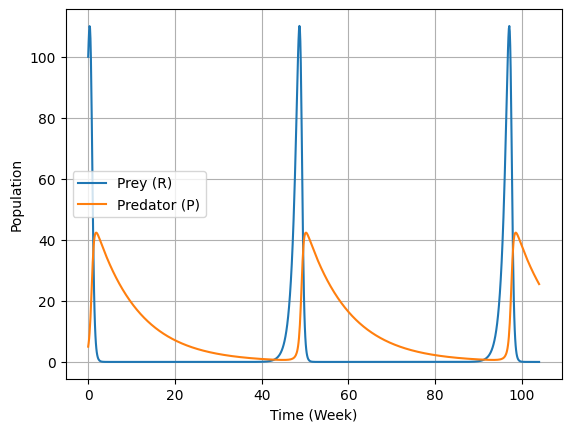

In [20]:
def lotka_volterra(y, t, r, a, s, b):
    R, P = y
    dRdt = r * R - a * R * P
    dPdt = -s * P + b * R * P
    return [dRdt, dPdt]

# Initial populations of prey (R) and predator (P)
R0 = 100  
P0 = 5    

# Rate constants
r = 1.0   
a = 0.1   
s = 0.1  
b = 0.02  

# Time points
t = np.linspace(0, 104, 1000)

# Solve the Lotka-Volterra equations
solution = odeint(lotka_volterra, [R0, P0], t, args=(r, a, s, b))

# Plot the results
plt.plot(t, solution[:, 0], label='Prey (R)')
plt.plot(t, solution[:, 1], label='Predator (P)')
plt.xlabel('Time (Week)')
plt.ylabel('Population')
plt.legend()
plt.grid(True)
plt.savefig('PredatorPrey.png',bbox_inches='tight')
plt.show()